# Roofs with heights

This notebook goes a step past footprints to LoD2 building models. Each roof is split into flat
faces, and each face gets a fitted plane, which gives you pitch and height and a 3D mesh. Roofs
need a height input, a normalised DSM (nDSM) of metres above ground, as a fourth channel next to
RGB. RGB alone wasn't viable in
[E049](https://github.com/DPIRD-DMA/ManySeg/tree/main/experiments/E049_lod2_rgb_height).

As in the [footprints notebook](03_vector_footprints.ipynb), **no trained model appears here**.
The houses are synthetic and the scene's targets stand in for a trained model's outputs. The nDSM
is a real input to the decoder, though, so the height test below exercises the real plane fit. It
runs on a CPU in under a minute with nothing to download.

Vector outputs are experimental, so names and defaults may change before 1.0. You need
`pip install "manyseg[vectors]" matplotlib`.

In [1]:
import json
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import shapely
import torch
from manyseg import create_model
from manyseg.vectors import (
    Scene,
    block_decoder,
    corner_line_heads,
    decode_scene,
    roof_face_targets,
    to_pixels,
)
from matplotlib.patches import Polygon as PolygonPatch
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10})
BLUE, ORANGE = "#1f6fb4", "#d9480f"

## Roof faces and their heights

The scene is 384 x 384 px at 0.25 m in the Dutch RD grid. It has two gable roofs, two hip roofs and
one flat roof. Each face comes with its plane, `z = a X + b Y + c`, which we use to build the nDSM.
In practice the nDSM would be a surface model minus a terrain model, resampled to the image grid.

In [2]:
PX = 0.25
TRANSFORM = (PX, 0.0, 136_000.0, 0.0, -PX, 456_000.0)
CRS = "EPSG:28992"
SHAPE = (384, 384)
X0, Y0 = 136_000.0, 456_000.0


def gable(left, top, w, d, eave=3.0, slope=0.6):
    xa, xb, ya, ym, yb = X0 + left, X0 + left + w, Y0 - top, Y0 - top - d / 2, Y0 - top - d
    ridge = eave + slope * d / 2
    return [(shapely.box(xa, ym, xb, ya), (0.0, -slope, ridge + slope * ym)),
            (shapely.box(xa, yb, xb, ym), (0.0, slope, ridge - slope * ym))]


def hip(left, top, w, d, eave=3.5, slope=0.6):
    xa, xb, ya, yb = X0 + left, X0 + left + w, Y0 - top, Y0 - top - d
    h = d / 2
    a, b, c, e = (xa, ya), (xb, ya), (xb, yb), (xa, yb)
    r1, r2 = (xa + h, ya - h), (xb - h, ya - h)
    return [(shapely.Polygon([a, b, r2, r1]), (0.0, -slope, eave + slope * ya)),
            (shapely.Polygon([r1, r2, c, e]), (0.0, slope, eave - slope * yb)),
            (shapely.Polygon([a, r1, e]), (slope, 0.0, eave - slope * xa)),
            (shapely.Polygon([b, c, r2]), (-slope, 0.0, eave + slope * xb))]


truth = [*gable(6, 6, 16, 10), *gable(28, 40, 14, 9), *hip(52, 52, 20, 12), *hip(8, 66, 18, 10),
         (shapely.box(X0 + 60, Y0 - 30, X0 + 80, Y0 - 14), (0.0, 0.0, 9.0))]


def make_ndsm():
    """Heights above ground at pixel centres, 0 off the roofs."""
    yy, xx = np.mgrid[0 : SHAPE[0], 0 : SHAPE[1]] + 0.5
    X, Y = X0 + PX * xx, Y0 - PX * yy
    z = np.zeros(SHAPE, np.float32)
    for face, (a, b, c) in truth:
        inside = shapely.contains_xy(face, X, Y)
        z[inside] = (a * X + b * Y + c)[inside]
    return z


height = make_ndsm()
faces = to_pixels([face for face, _ in truth], TRANSFORM, SHAPE, crs=CRS, raster_crs=CRS)
targets = roof_face_targets(faces, SHAPE)
print(f"{len(faces)} faces, nDSM up to {height.max():.1f} m")

13 faces, nDSM up to 9.0 m


## Faces become targets

These are the same corner-line targets as footprints, with one difference. Faces that share a ridge
stay separate instances, so the boundary head has to find ridges and hips as well as eaves.

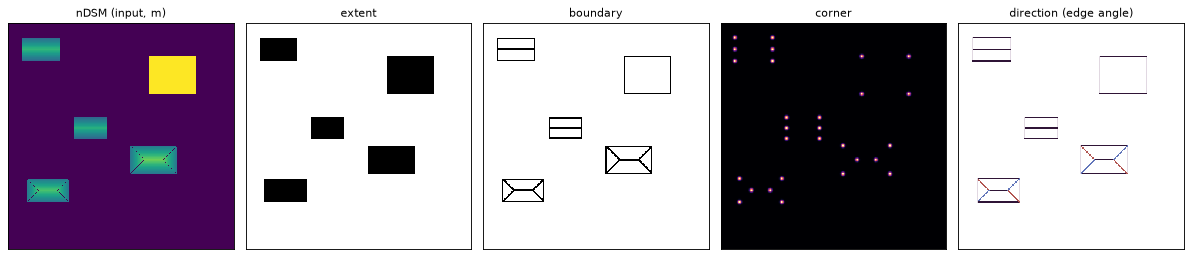

In [3]:
angle = 0.5 * np.arctan2(targets["direction"][1], targets["direction"][0])
panels = [("nDSM (input, m)", height, "viridis"), ("extent", targets["extent"], "gray_r"),
          ("boundary", targets["boundary"], "gray_r"), ("corner", targets["corner"], "magma"),
          ("direction (edge angle)", np.ma.masked_where(targets["direction_mask"] == 0, angle),
           "twilight")]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
for ax, (title, image, cmap) in zip(axes, panels):
    ax.imshow(image, cmap=cmap, interpolation="nearest")
    ax.set(title=title, xticks=[], yticks=[])
fig.tight_layout()

## The model

It's the corner-line preset with four input channels. We build it only to check its output shapes.
The decoder also reads the nDSM directly. That input isn't a prediction, so `fields["height"]` stays
the same when you swap in a trained model.

In [4]:
LOGIT_HEADS = ("extent", "boundary", "corner")
model = create_model(backbone="resnet18", pretrained=False, in_channels=4,
                     heads=corner_line_heads()).eval()
ndsm_tile = torch.from_numpy(height[None, None, :128, :128])
sample = torch.cat([torch.rand(1, 3, 128, 128), ndsm_tile], 1)
with torch.no_grad():
    out = model(sample)
print({head: tuple(v.shape) for head, v in out.items()})

# A trained model's stitched scene would go here:
# fields = {k: (v.sigmoid() if k in LOGIT_HEADS else v)[0].numpy() for k, v in out.items()}
fields = {k: targets[k] for k in ("extent", "boundary", "distance", "corner", "direction")}
fields["height"] = height

{'extent': (1, 1, 128, 128), 'boundary': (1, 1, 128, 128), 'distance': (1, 1, 128, 128), 'corner': (1, 1, 128, 128), 'direction': (1, 2, 128, 128)}


## Decode faces and fit planes

Each record has a polygon, a plane and a mesh. Planes are in scene pixels (corners at integers) and
metres: the centre of pixel `(row, col)` has `z = a * (col + 0.5) + b * (row + 0.5) + c`, so dividing
`a` and `b` by the pixel size gives the pitch. Every sloped roof here
was built at atan(0.6), which is 31 degrees, and the flat roof at 0, so this is easy to check.

13 faces from 13; same as decoding in one go: True
pitch of each face (degrees): [0.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0, 31.0]


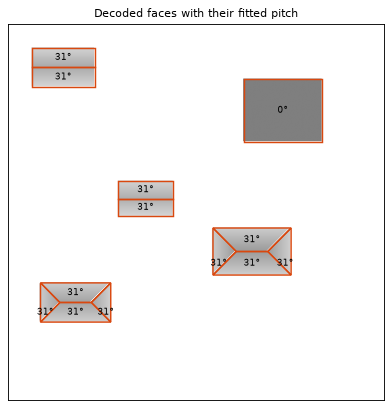

In [5]:
scene = Scene(*SHAPE, transform=TRANSFORM, crs=CRS)
decoder = block_decoder("roofs")
records = decode_scene(fields, decoder, block=192, halo=64, scene=scene)
whole = decode_scene(fields, decoder, scene=scene)
same = len(records) == len(whole) and all(
    shapely.equals_exact(a["geometry"], b["geometry"], 0) and a["plane"] == b["plane"]
    for a, b in zip(records, whole))
print(f"{len(records)} faces from {len(faces)}; same as decoding in one go: {same}")


def pitch(plane):
    return np.degrees(np.arctan(np.hypot(plane[0], plane[1]) / PX))


print("pitch of each face (degrees):", sorted(round(float(pitch(r["plane"])), 1) for r in records))

fig, ax = plt.subplots(figsize=(6.2, 5.2))
ax.imshow(height, cmap="gray_r", vmin=0, vmax=height.max() * 2)
for r in records:
    p = r["geometry"]
    ax.add_patch(PolygonPatch(np.asarray(p.exterior.coords), fill=False, ec=ORANGE, lw=1.3))
    x, y = p.representative_point().coords[0]
    ax.text(x, y, f"{pitch(r['plane']):.0f}°", ha="center", va="center", fontsize=8)
ax.set(title="Decoded faces with their fitted pitch", xticks=[], yticks=[])
fig.tight_layout()

## The 3D view

`records.write(..., mesh=True)` writes each face with a height on every vertex. This plot reads that
file back, so what you see is what you'd load into a GIS. Colour shows height, and the height axis
is exaggerated so the roof shapes are easy to see. The mesh holds roofs only, with no walls.

13 2D faces with properties: ['id', 'part', 'plane_a', 'plane_b', 'plane_c']
first 3D vertex (X, Y, z): [136006.0, 455994.0, 3.000000046748244]


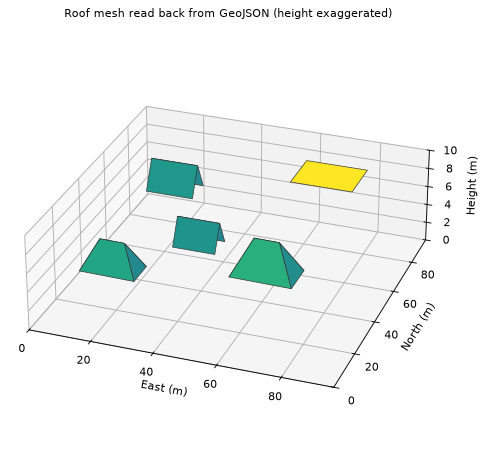

In [6]:
with TemporaryDirectory() as tmp:
    mesh_path = records.write(Path(tmp) / "roof_mesh.geojson", mesh=True)
    faces_path = records.write(Path(tmp) / "roof_faces.geojson")
    mesh = json.loads(Path(mesh_path).read_text())
    flat = json.loads(Path(faces_path).read_text())
print(len(flat["features"]), "2D faces with properties:", list(flat["features"][0]["properties"]))
print("first 3D vertex (X, Y, z):", mesh["features"][0]["geometry"]["coordinates"][0][0])

rings = [np.asarray(f["geometry"]["coordinates"][0]) for f in mesh["features"]]
rings = [ring - [X0, Y0 - SHAPE[0] * PX, 0] for ring in rings]
tops = np.array([ring[:, 2].mean() for ring in rings])
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.add_collection3d(Poly3DCollection(rings, facecolors=plt.cm.viridis(tops / tops.max()),
                                     edgecolors="#333333", linewidths=0.6))
ax.set(xlim=(0, 96), ylim=(0, 96), zlim=(0, 10), xlabel="East (m)", ylabel="North (m)",
       zlabel="Height (m)", title="Roof mesh read back from GeoJSON (height exaggerated)")
ax.set_box_aspect((96, 96, 32))
ax.view_init(elev=28, azim=-70)
fig.tight_layout()

## How noisy can the heights be?

Real surface models are noisy, so here we add noise to the nDSM and keep the face outlines perfect.
This isolates the plane fit, and because the nDSM is a true input, it's a fairer test than the
damaged outputs in the other notebooks. It says nothing about how well a model finds the faces. For
each noise level we match decoded faces to true faces and compare pitch and height. A plane fitted
over thousands of pixels averages most of the noise away, and this is the clean case for that:
noise here is independent per pixel, and a real DSM's errors are often smoother and harder to remove.

noise 0.00 m: pitch error 0.00 deg, height RMSE 0.000 m
noise 0.10 m: pitch error 0.15 deg, height RMSE 0.008 m


noise 0.25 m: pitch error 0.37 deg, height RMSE 0.020 m
noise 0.50 m: pitch error 0.74 deg, height RMSE 0.040 m


noise 1.00 m: pitch error 1.47 deg, height RMSE 0.080 m


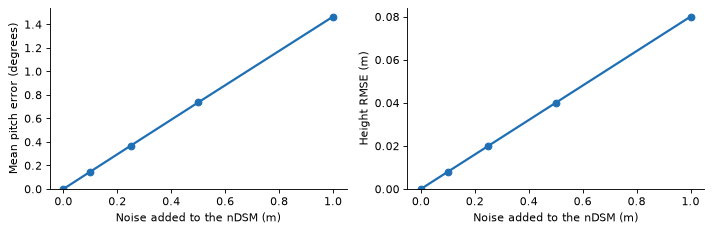

In [7]:
def score(records):
    """Mean absolute pitch error (degrees) and height RMSE (m), matching faces by overlap."""
    yy, xx = np.mgrid[0 : SHAPE[0], 0 : SHAPE[1]] + 0.5
    pitch_errors, height_errors = [], []
    for r in records:
        overlaps = [r["geometry"].intersection(f).area for f in faces]
        i = int(np.argmax(overlaps))
        a, b, _ = truth[i][1]
        pitch_errors.append(abs(pitch(r["plane"]) - np.degrees(np.arctan(np.hypot(a, b)))))
        inside = shapely.contains_xy(faces[i], xx, yy)
        plane = r["plane"][0] * xx + r["plane"][1] * yy + r["plane"][2]
        height_errors.append((plane[inside] - height[inside]) ** 2)
    return np.mean(pitch_errors), np.sqrt(np.concatenate(height_errors).mean())


noises = [0.0, 0.1, 0.25, 0.5, 1.0]
results = []
for noise in noises:
    rng = np.random.default_rng(0)
    noisy = dict(fields)
    noisy["height"] = height + rng.normal(0, noise, SHAPE).astype(np.float32) * (height > 0)
    decoded = decode_scene(noisy, decoder, block=192, halo=64, scene=scene)
    results.append(score(decoded))
    print(f"noise {noise:.2f} m: pitch error {results[-1][0]:.2f} deg, "
          f"height RMSE {results[-1][1]:.3f} m")

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
labels = ("Mean pitch error (degrees)", "Height RMSE (m)")
for ax, values, label in zip(axes, zip(*results), labels):
    ax.plot(noises, values, marker="o", c=BLUE, lw=2)
    ax.set(xlabel="Noise added to the nDSM (m)", ylabel=label, ylim=(0, None))
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

## Where to go next

* The training losses are in
  [`examples/vector_presets.py`](https://github.com/DPIRD-DMA/ManySeg/blob/main/examples/vector_presets.py).
* See the other vector outputs: [footprints](03_vector_footprints.ipynb),
  [fields](04_vector_fields.ipynb), [roads](05_vector_roads.ipynb) and
  [points](07_vector_points.ipynb).